# 08 - Little Lessons

Registered passages -> saved storyboard -> code validation -> cards -> narration -> video -> human scene review -> approved library. Six current storyboards pass source fidelity. The owner explicitly approved every scene of holding v3 and swaddling v5 on 2026-11-01, completing all six current scene approvals. The separate 39-case dataset keeps **draft intent labels** and unchanged routing results. Logic lives in `evals/lessons_eval.py` and `nestling/lessons/`. This notebook reads local saved artifacts only; no paid or network calls.


In [1]:
import os
os.environ["LANGSMITH_TRACING"] = "false"

from evals import lessons_eval
from nestling.lessons import library

lesson = library.get("holding")
board = lesson["storyboard"]
print({"lesson_id": board["lesson_id"], "version": board["version"], "steps": len(board["scenes"]), "sources": board["sources"]})
print(lessons_eval.review_summary(board, lesson["review"]))


{'lesson_id': 'holding', 'version': 3, 'steps': 4, 'sources': ['NHS-RWT-HOLDING']}
{'status': 'reviewed', 'n_scenes': 4, 'n_reviewed': 4, 'pass_rate': 1.0, 'scenes': [{'step_no': 1, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in the async answer on 2026-11-01.'}, {'step_no': 2, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in the async answer on 2026-11-01.'}, {'step_no': 3, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in the async answer on 2026-11-01.'}, {'step_no': 4, 'passed': True, 'notes': 'Owner explicitly approved every scene of this exact storyboard version in the async answer on 2026-11-01.'}], 'approved': True}


The saved live evaluation is separate from the current local media inventory: 39/39 routing, 3/3 danger escalation and six current fidelity passes; cumulative evaluation spend is INR1.8918 under INR20. Earlier raw verdicts, including swaddling v3/v4 False results, remain in history. General holding and complete swaddling use registered citation-only local PDFs without Pinecone writes. Narration allows 20 words, captions 8; burned-in narration is preserved fully or rendering fails clearly. Human reviews, draft intent labels and calibration remain independent gates. Narration estimates (holding INR4.92, swaddling INR12.60 cumulative) are separate from evaluation and the unchanged INR244.0804 quality ledger. The display below refreshes only local review/render inventory; no live evaluation is run.


In [2]:
result = lessons_eval.latest()
fields = ("dataset", "label_status", "n_cases", "routing_accuracy", "danger_escalation_accuracy", "n_errors", "step_fidelity", "n_storyboards_judged", "judge", "total_live_cost_inr", "budget_cap_inr", "budget_accounted_inr", "experiment")
print({key: result.get(key) for key in fields})
print("Preserved prior version records:", len(result.get("version_history", [])))
for item in result["lessons"]:
    current = library.get(item["lesson_id"])
    render = lessons_eval.render_summary(current["folder"] / "renders")
    print({"lesson_id": item["lesson_id"], "version": current["storyboard"]["version"],
           "human_review": lessons_eval.review_summary(current["storyboard"], current["review"])["status"],
           "saved_fidelity": item["fidelity"].get("faithful"),
           "render_seconds": render.get("seconds"), "current_render_cost_inr": render.get("cost_inr"),
           "reviewed_on": render.get("reviewed_on")})


{'dataset': 'nestling-lessons-v1', 'label_status': 'draft; pending owner review', 'n_cases': 39, 'routing_accuracy': 1.0, 'danger_escalation_accuracy': 1.0, 'n_errors': 0, 'step_fidelity': 1.0, 'n_storyboards_judged': 6, 'judge': 'Qwen/Qwen3-235B-A22B-Instruct-2507', 'total_live_cost_inr': 1.8918, 'budget_cap_inr': 20.0, 'budget_accounted_inr': 1.8918, 'experiment': 'nestling-lessons-f15c178e'}
Preserved prior version records: 8
{'lesson_id': 'bathing', 'version': 1, 'human_review': 'reviewed', 'saved_fidelity': True, 'render_seconds': 21.7, 'current_render_cost_inr': 0.0, 'reviewed_on': '2026-11-01'}
{'lesson_id': 'burping', 'version': 1, 'human_review': 'reviewed', 'saved_fidelity': True, 'render_seconds': 18.4, 'current_render_cost_inr': 0.0, 'reviewed_on': '2026-11-01'}
{'lesson_id': 'cord_care', 'version': 4, 'human_review': 'reviewed', 'saved_fidelity': True, 'render_seconds': 19.1, 'current_render_cost_inr': 0.0, 'reviewed_on': '2026-11-01'}
{'lesson_id': 'holding', 'version': 3

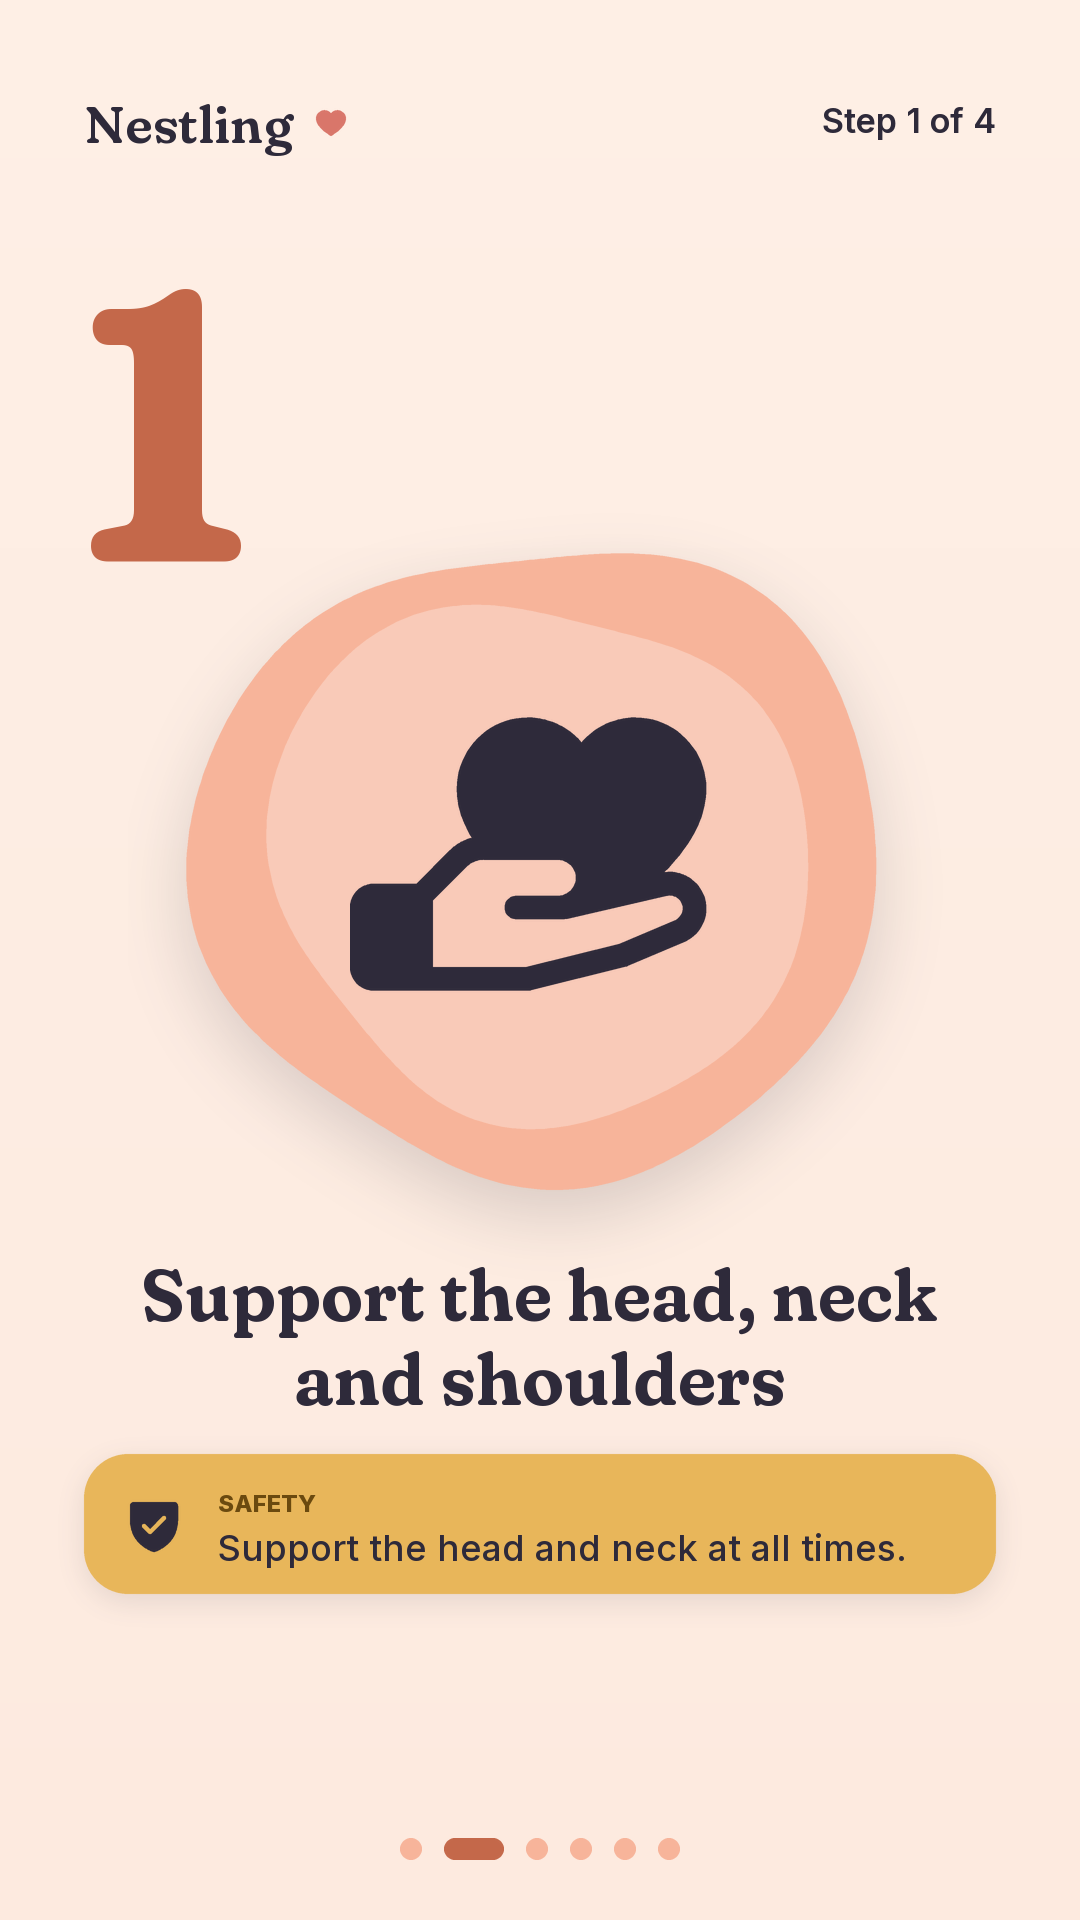

In [3]:
from IPython.display import display, Image

display(Image(filename=str(lesson["folder"] / "renders" / "card_2.png"), width=270))